<div style="padding-left: 10em; font-size: 1.2em; line-height: 1.6; margin-bottom: 2.5em; margin-top: 1.5em;">

## Demonstration — Beslutsstöd i Praktiken

- **Syfte:** Simulera hur hotellets personal varnas för riskbokningar i realtid
- **Metod:** Slutmodell (Random Forest) kombinerat med förklarbar AI (SHAP)
- **Nytta:** Från "svart låda" till konkreta åtgärder för intäkts- och receptionspersonal

</div>

---

<div style="padding-left: 10em; font-size: 1.2em; line-height: 1.6; margin-bottom: 2.5em; margin-top: 1.5em;">

## Varför XAI (Explainable AI)?

- **Black Box-problemet:** Komplexa modeller ger högre precision, men döljer hur besluten fattas
- **Transparens och tolkbarhet:** Göra avancerad maskininlärning förståelig för mänskliga användare
- **Förtroende och acceptans:** Beslutsfattare måste lita på modellens resonemang för att våga agera på det
- **Felsökning och kvalitet:** Möjliggör granskning av snedvridningar (bias), felaktiga antaganden och dataläckage

</div>

---

<div style="padding-left: 10em; font-size: 1.2em; line-height: 1.6; margin-bottom: 2.5em; margin-top: 1.5em;">

## SHAP och TreeExplainer i korthet

- **Rättvis bidragsfördelning:** Beräknar hur mycket varje enskild variabel driver prediktionen uppåt eller nedåt
- **Lokal och global tolkbarhet:** Kan förklara både enskilda observationer och modellens generella beteende
- **Additiv egenskap:** Varje variabels bidrag plussas på eller dras ifrån modellens baslinje ($E[f(X)]$)
- **TreeExplainer:** En specialiserad, snabb algoritm för trädbaserade modeller (t.ex. Random Forest och XGBoost

</div>

---

In [1]:
import os

# Sätt arbetskatalog till projektroten om notebooken körs från notebooks/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
    
import pandas as pd
from src.evaluation import plot_booking_shap_waterfall
from src.model_io import load_model_artifacts
from src.preprocessing import split_features_target

---

<div style="padding-left: 10em; font-size: 1.2em; line-height: 1.6; margin-bottom: 2.5em; margin-top: 1.5em;">

## Ladda artefakter & simulera ny bokning

- **Scenario:** Ny bokning registreras i systemet utan framtida facit
- **Status:** Rådata skickas direkt in i modellens pipeline för bedömning

</div>

---

In [2]:
# Ladda tränad modell och anpassad preprocessor
rf_model, preprocessor = load_model_artifacts()

2026-10-27 20:30:45 [INFO] src.model_io: Läser in modellartefakter från outputs\models...
2026-10-27 20:30:45 [INFO] src.model_io: Artefakter inlästa framgångsrikt.


In [3]:
# Läs in den simulerade inkommande bokningen
booking = pd.read_csv("data/demo_booking.csv", index_col=0)

print(f"Bokning mottagen i systemet (Boknings-ID: #{booking.index[0]}):")
display(booking.drop(columns=["is_canceled"]))

Bokning mottagen i systemet (Boknings-ID: #9076):


,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date,booking_date
9076,Resort Hotel,103,2017,March,13,27,1,1,2,0.0,...,0.0,0,Transient,73.0,0,0,Canceled,2016-12-23,2017-03-27,2016-12-14


---

<div style="padding-left: 8em; font-size: 1.2em; line-height: 1.6; margin-bottom: 2.5em; margin-top: 1.5em;">

## Prediktion & Operativ Tröskel

- **Scenario:** Högsäsong / högt tryck på hotellet och personalen
- **Kapacitetsanpassad gräns:** Tröskeln sätts högre ($\ge 65\,\%$) så att personalen enbart larmas om de mer akuta riskärendena
- **Systemets utfall:** Med en predicerad risk på **70,9 %** flaggas ärendet direkt för åtgärd

</div>

---

In [4]:
# Förbered data och beräkna sannolikhet
X, _ = split_features_target(booking, include_deposit_type=False)
X_processed = preprocessor.transform(X)
predicted_risk = rf_model.predict_proba(X_processed)[0, 1]

# Operativ tröskel anpassad för sommar/högsäsong (endast de mest akuta riskerna hanteras)
ACTION_THRESHOLD = 0.65

print(f"Predicerad avbokningsrisk: {predicted_risk:.1%}")
print(
    f"Systemstatus:             "
    f" {'FLAGGAD FÖR ÅTGÄRD' if predicted_risk >= ACTION_THRESHOLD else 'Normal risk'}"
)

Predicerad avbokningsrisk: 70.9%
Systemstatus:              FLAGGAD FÖR ÅTGÄRD


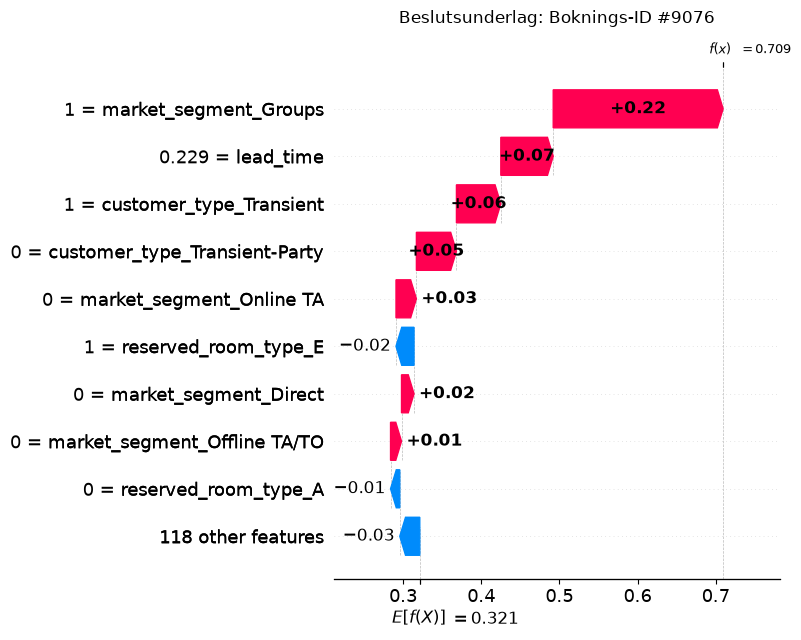

In [5]:
# Rita vattenfallsdiagrammet
plot_booking_shap_waterfall(
    rf_model,
    preprocessor,
    X,
    title=f"Beslutsunderlag: Boknings-ID #{booking.index[0]}",
)

---

<div style="padding-left: 8em; font-size: 1.2em; line-height: 1.6;  margin-bottom: 2.5em; margin-top: 1.5em;">

## Verksamhetsperspektivet

- **Huvudsakliga riskdrivare:**
  - **Gruppavtal (`market_segment_Groups`):** Resebyrå-/gruppblock (+22 %)<br>
    Historiskt sett förknippat med hög avbokningsgrad.
  - **Kundprofil (+11 % sammantaget):** Fristående gäst (`Transient`, +6 %)<br>
    Saknar dessutom sällskapskoppling (`not Transient-Party`, +5 %).
  - **Framförhållning (`lead_time` = 103 dagar):** Lång ledtid (+7 %)<br>
    Ökar sannolikheten för ändrade resplaner över tid.
- **Konkreta åtgärder för personalen (Högsäsong):**
  - **Personlig kontakt:** Skicka automatiserad ankomstbekräftelse med svarslänk 30 dagar före ankomst
  - **Incentiv:** Erbjuda kostnadsfri tidig incheckning eller måltidsförmån vid aktiv bekräftelse
  - **Intäktsstyrning (Revenue Management):** Planera kontrollerad överbokning på rumstyp E<br>
    Minimerar risken för outnyttjad kapacitet under högsäsong.

</div>